In [1]:
import pandas as pd

cols = ["id", "project", "cat2", "forg", "center", "year", "mode",
        "rely", "data", "cplx", "time", "stor", "virt", "turn",
        "acap", "aexp", "pcap", "vexp", "lexp", "modp", "tool",
        "sced", "equivphyskloc", "act_effort"]

df = pd.read_csv("data/nasa93.csv", skiprows=25, header=None, names=cols)

In [2]:
a = df["mode"].map({"organic": 2.4, "semidetached": 3.0, "embedded": 3.6})
b = df["mode"].map({"organic": 1.05, "semidetached": 1.12, "embedded": 1.20})

df["estimate"] = a * df["equivphyskloc"] ** b
df["overrun"] = (df["act_effort"] > df["estimate"]).astype(int)

print(df.shape)
print(df["overrun"].value_counts())

(93, 26)
overrun
1    49
0    44
Name: count, dtype: int64


In [3]:
print(df.dtypes)

rating_cols = ["rely", "data", "cplx", "time", "stor", "virt", "turn",
               "acap", "aexp", "pcap", "vexp", "lexp", "modp", "tool", "sced"]
for c in rating_cols:
    print(c, sorted(df[c].unique()))

id                 int64
project              str
cat2                 str
forg                 str
center               str
year               int64
mode                 str
rely                 str
data                 str
cplx                 str
time                 str
stor                 str
virt                 str
turn                 str
acap                 str
aexp                 str
pcap                 str
vexp                 str
lexp                 str
modp                 str
tool                 str
sced                 str
equivphyskloc    float64
act_effort       float64
estimate         float64
overrun            int64
dtype: object
rely ['h', 'l', 'n', 'vh']
data ['h', 'l', 'n', 'vh']
cplx ['h', 'l', 'n', 'vh', 'xh']
time ['h', 'n', 'vh', 'xh']
stor ['h', 'n', 'vh', 'xh']
virt ['h', 'l', 'n']
turn ['h', 'l', 'n', 'vh']
acap ['h', 'n', 'vh']
aexp ['h', 'l', 'n', 'vh']
pcap ['h', 'n', 'vh']
vexp ['h', 'l', 'n', 'vl']
lexp ['h', 'l', 'n', 'vl']
modp ['h', 'l', 'n',

In [4]:
order = {"vl": 0, "l": 1, "n": 2, "h": 3, "vh": 4, "xh": 5}

In [5]:
print(df[rating_cols].isna().sum().sum())
df[rating_cols].head()

0


,rely,data,cplx,time,stor,virt,turn,acap,aexp,pcap,vexp,lexp,modp,tool,sced
0,h,l,h,xh,xh,l,h,h,h,h,n,h,h,h,n
1,n,l,h,n,n,l,l,h,vh,vh,n,h,n,n,n
2,n,l,h,n,n,l,l,h,vh,h,n,h,n,n,n
3,n,l,h,n,n,l,l,h,vh,vh,n,h,n,n,n
4,n,l,h,n,n,l,l,h,vh,n,n,l,n,n,n


In [6]:
for c in ["project", "cat2", "forg", "center", "mode"]:
    print(c, df[c].nunique())
    print(df[c].value_counts().head(10))

project 8
project
Y      38
X      23
gal    13
de      8
spl     4
hst     3
slp     3
erb     1
Name: count, dtype: int64
cat2 14
cat2
avionicsmonitoring     30
missionplanning        20
Avionics               11
monitor_control         8
simulation              4
operatingsystem         4
realdataprocessing      3
datacapture             3
batchdataprocessing     2
science                 2
Name: count, dtype: int64
forg 2
forg
g    80
f    13
Name: count, dtype: int64
center 5
center
_5    39
_2    37
_1    12
_6     3
_3     2
Name: count, dtype: int64
mode 3
mode
semidetached    69
embedded        21
organic          3
Name: count, dtype: int64


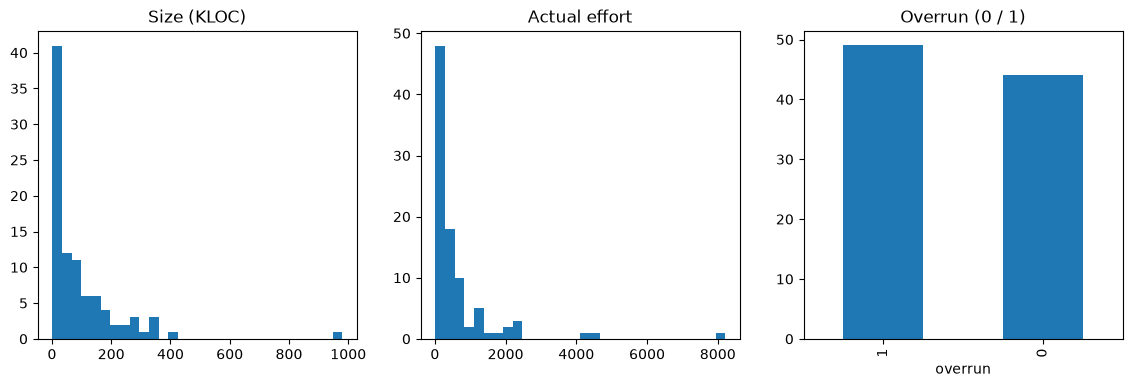

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].hist(df["equivphyskloc"], bins=30)
ax[0].set_title("Size (KLOC)")
ax[1].hist(df["act_effort"], bins=30)
ax[1].set_title("Actual effort")
df["overrun"].value_counts().plot(kind="bar", ax=ax[2])
ax[2].set_title("Overrun (0 / 1)")
plt.show()

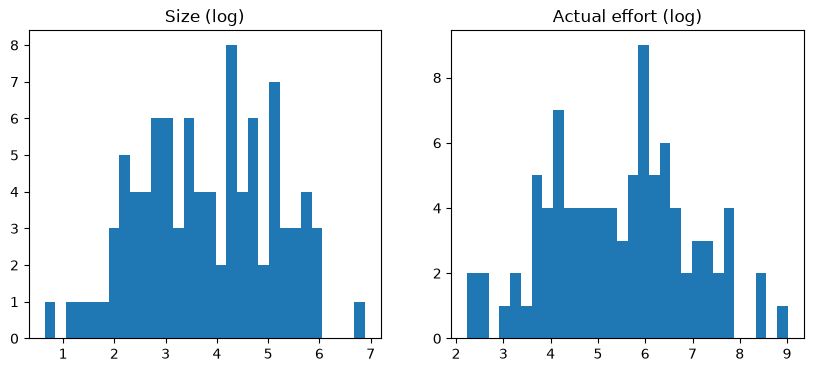

In [8]:
import numpy as np

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(np.log1p(df["equivphyskloc"]), bins=30)
ax[0].set_title("Size (log)")
ax[1].hist(np.log1p(df["act_effort"]), bins=30)
ax[1].set_title("Actual effort (log)")
plt.show()

In [9]:
print(df[rating_cols].isna().sum().sum())

0


In [10]:
df["mode_num"] = df["mode"].map({"organic": 0, "semidetached": 1, "embedded": 2})

features = rating_cols + ["equivphyskloc", "mode_num"]
X = df[features]
y_class = df["overrun"]
y_effort = df["act_effort"]

print(X.shape)
print(X.dtypes.value_counts())
print(X.isna().sum().sum())

(93, 17)
str        15
float64     1
int64       1
Name: count, dtype: int64
0


In [11]:
print(df[rating_cols].dtypes)
print(df[rating_cols].head())

rely    str
data    str
cplx    str
time    str
stor    str
virt    str
turn    str
acap    str
aexp    str
pcap    str
vexp    str
lexp    str
modp    str
tool    str
sced    str
dtype: object
  rely data cplx time stor virt turn acap aexp pcap vexp lexp modp tool sced
0    h    l    h   xh   xh    l    h    h    h    h    n    h    h    h    n
1    n    l    h    n    n    l    l    h   vh   vh    n    h    n    n    n
2    n    l    h    n    n    l    l    h   vh    h    n    h    n    n    n
3    n    l    h    n    n    l    l    h   vh   vh    n    h    n    n    n
4    n    l    h    n    n    l    l    h   vh    n    n    l    n    n    n


In [12]:
rating_map = {
    "vl": 0,
    "l": 1,
    "n": 2,
    "h": 3,
    "vh": 4,
    "xh": 5
}

df[rating_cols] = df[rating_cols].replace(rating_map).astype(int)

In [13]:
print(df[rating_cols].dtypes)
print(df[rating_cols].head())

rely    int64
data    int64
cplx    int64
time    int64
stor    int64
virt    int64
turn    int64
acap    int64
aexp    int64
pcap    int64
vexp    int64
lexp    int64
modp    int64
tool    int64
sced    int64
dtype: object
   rely  data  cplx  time  stor  virt  turn  acap  aexp  pcap  vexp  lexp  \
0     3     1     3     5     5     1     3     3     3     3     2     3   
1     2     1     3     2     2     1     1     3     4     4     2     3   
2     2     1     3     2     2     1     1     3     4     3     2     3   
3     2     1     3     2     2     1     1     3     4     4     2     3   
4     2     1     3     2     2     1     1     3     4     2     2     1   

   modp  tool  sced  
0     3     3     2  
1     2     2     2  
2     2     2     2  
3     2     2     2  
4     2     2     2  


In [14]:
df["mode_num"] = df["mode"].map({
    "organic": 0,
    "semidetached": 1,
    "embedded": 2
})

features = rating_cols + ["equivphyskloc", "mode_num"]

X = df[features]
y_class = df["overrun"]
y_effort = df["act_effort"]

print(X.shape)
print(X.dtypes.value_counts())
print(X.isna().sum().sum())

(93, 17)
int64      16
float64     1
Name: count, dtype: int64
0


**Stage 2:**

 **Data Cleaning & Analysis**

**- Dataset:** 93 software projects.

**- Skewness:** Used "log1p()" to balance size and effort distributions.

**- Rating Columns:** Converted text ratings into numbers (0–5).

**- Input Features:** Selected 17 columns (15 ratings, size, and mode).

**- Data Leakage:** Excluded actual effort from classification inputs.